In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('C:\\Users\\Ritik Chauhan\\OneDrive\\Desktop\\pythonp\\Customer Churn Analysis\\data\\cleaneddataset.csv')

print(df.shape)
print(df.dtypes)
print(df['Churn'].value_counts(normalize=True))

(7043, 24)
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
ChurnFlag             int64
TenureBucket         object
NumServices           int64
dtype: object
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [2]:
df[['ChurnFlag', 'TenureBucket', 'NumServices']].head()

,ChurnFlag,TenureBucket,NumServices
0,0,0-1 yr,1
1,0,2-4 yr,2
2,1,0-1 yr,2
3,0,2-4 yr,3
4,1,0-1 yr,0


In [3]:
# Drop the identifier — customerID has no predictive signal, it's just a row ID
df_model = df.drop(columns=['customerID'])

# Target: use ChurnFlag (already 1/0 from Stage 1) instead of the string 'Churn' column
y = df_model['ChurnFlag']
X = df_model.drop(columns=['Churn', 'ChurnFlag'])

# Find the categorical (string/object) columns
cat_cols = X.select_dtypes(include='object').columns.tolist()
print("Categorical columns:", cat_cols)

# Convert each to pandas 'category' dtype — this is the actual instruction to XGBoost
for col in cat_cols:
    X[col] = X[col].astype('category')

X.dtypes

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureBucket']


gender              category
SeniorCitizen          int64
Partner             category
Dependents          category
tenure                 int64
PhoneService        category
MultipleLines       category
InternetService     category
OnlineSecurity      category
OnlineBackup        category
DeviceProtection    category
TechSupport         category
StreamingTV         category
StreamingMovies     category
Contract            category
PaperlessBilling    category
PaymentMethod       category
MonthlyCharges       float64
TotalCharges         float64
TenureBucket        category
NumServices            int64
dtype: object

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # hold back 20% for testing
    stratify=y,         # preserve the 26.54% churn ratio in both sets
    random_state=42      # makes the split reproducible — same split every time you rerun
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train churn rate:", y_train.mean())
print("Test churn rate:", y_test.mean())

Train shape: (5634, 21)
Test shape: (1409, 21)
Train churn rate: 0.2653532126375577
Test churn rate: 0.2654364797728886


In [5]:
from xgboost import XGBClassifier

model = XGBClassifier(
    enable_categorical=True,   # tells XGBoost to use the pandas 'category' columns natively
    tree_method='hist',         # required for native categorical support
    random_state=42
)

model.fit(X_train, y_train)
print("Model trained.")

Model trained.


In [6]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score
)

# Predicted class labels (0 or 1)
y_pred = model.predict(X_test)

# Predicted probabilities (needed for ROC-AUC / PR-AUC, and later SHAP)
y_pred_proba = model.predict_proba(X_test)[:, 1]  # probability of class 1 (churn)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
print("PR-AUC (Average Precision):", average_precision_score(y_test, y_pred_proba))

Confusion Matrix:
[[904 131]
 [168 206]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.87      0.86      1035
       Churn       0.61      0.55      0.58       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.78      1409

ROC-AUC: 0.8238058332687489
PR-AUC (Average Precision): 0.6260898600720256


In [7]:
# Count how imbalanced the training set is
neg, pos = y_train.value_counts()
scale_pos_weight = neg / pos
print("scale_pos_weight:", scale_pos_weight)

# Retrain with this weighting
model_weighted = XGBClassifier(
    enable_categorical=True,
    tree_method='hist',
    scale_pos_weight=scale_pos_weight,
    random_state=42
)
model_weighted.fit(X_train, y_train)

# Re-evaluate exactly as before
y_pred_w = model_weighted.predict(X_test)
y_pred_proba_w = model_weighted.predict_proba(X_test)[:, 1]

print("Confusion Matrix (weighted):")
print(confusion_matrix(y_test, y_pred_w))
print("\nClassification Report (weighted):")
print(classification_report(y_test, y_pred_w, target_names=['No Churn', 'Churn']))
print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba_w))
print("PR-AUC:", average_precision_score(y_test, y_pred_proba_w))

scale_pos_weight: 2.768561872909699
Confusion Matrix (weighted):
[[822 213]
 [135 239]]

Classification Report (weighted):
              precision    recall  f1-score   support

    No Churn       0.86      0.79      0.83      1035
       Churn       0.53      0.64      0.58       374

    accuracy                           0.75      1409
   macro avg       0.69      0.72      0.70      1409
weighted avg       0.77      0.75      0.76      1409

ROC-AUC: 0.8163850784055389
PR-AUC: 0.6161336751621757


In [8]:
# Try a lower threshold on the weighted model's probabilities
threshold = 0.35
y_pred_custom = (y_pred_proba_w >= threshold).astype(int)

print(f"Threshold = {threshold}")
print(confusion_matrix(y_test, y_pred_custom))
print(classification_report(y_test, y_pred_custom, target_names=['No Churn', 'Churn']))

Threshold = 0.35
[[759 276]
 [ 89 285]]
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.76      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.74      0.75      1409



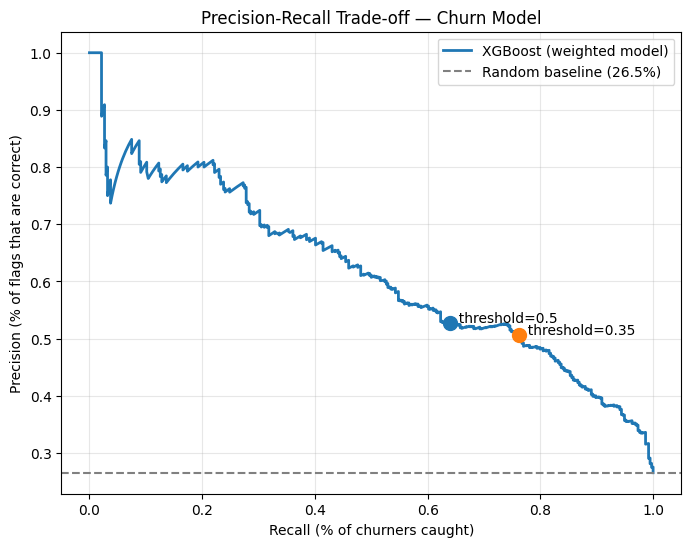

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba_w)

plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, label='XGBoost (weighted model)', linewidth=2)
plt.axhline(y=y_test.mean(), color='gray', linestyle='--',
            label=f'Random baseline ({y_test.mean():.1%})')

# Mark the two thresholds you already tested, so you can place them on the curve
for t in [0.5, 0.35]:
    idx = np.argmin(np.abs(thresholds - t))
    plt.scatter(recalls[idx], precisions[idx], s=100, zorder=5)
    plt.annotate(f'  threshold={t}', (recalls[idx], precisions[idx]))

plt.xlabel('Recall (% of churners caught)')
plt.ylabel('Precision (% of flags that are correct)')
plt.title('Precision-Recall Trade-off — Churn Model')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

# The ranges of hyperparameters to search over
param_dist = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5, 7],
    'reg_lambda': [0.1, 1, 5, 10]
}

base_model = XGBClassifier(
    enable_categorical=True,
    tree_method='hist',
    scale_pos_weight=scale_pos_weight,   # keep the imbalance fix from Step 6
    random_state=42
)

search = RandomizedSearchCV(
    base_model,
    param_distributions=param_dist,
    n_iter=30,              # try 30 random combinations (not all ~5,400 possible — too slow, and unnecessary)
    scoring='average_precision',   # PR-AUC — the honest metric from Step 5, not accuracy
    cv=5,                   # 5-fold cross-validation, as just explained
    random_state=42,
    n_jobs=-1                # use all CPU cores to speed this up
)

search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best cross-validated PR-AUC:", search.best_score_)

Best params: {'subsample': 1.0, 'reg_lambda': 5, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
Best cross-validated PR-AUC: 0.6680038232937273


In [11]:
import shap

# Use the best model found by the search (Step 7)
final_model = search.best_estimator_

# Create the SHAP explainer for our tree-based model
explainer = shap.TreeExplainer(final_model)

# Calculate the "receipt" for every customer in the test set
shap_values = explainer(X_test)

print("Done. Shape:", shap_values.shape)

c:\Users\Ritik Chauhan\OneDrive\Desktop\pythonp\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Done. Shape: (1409, 21)


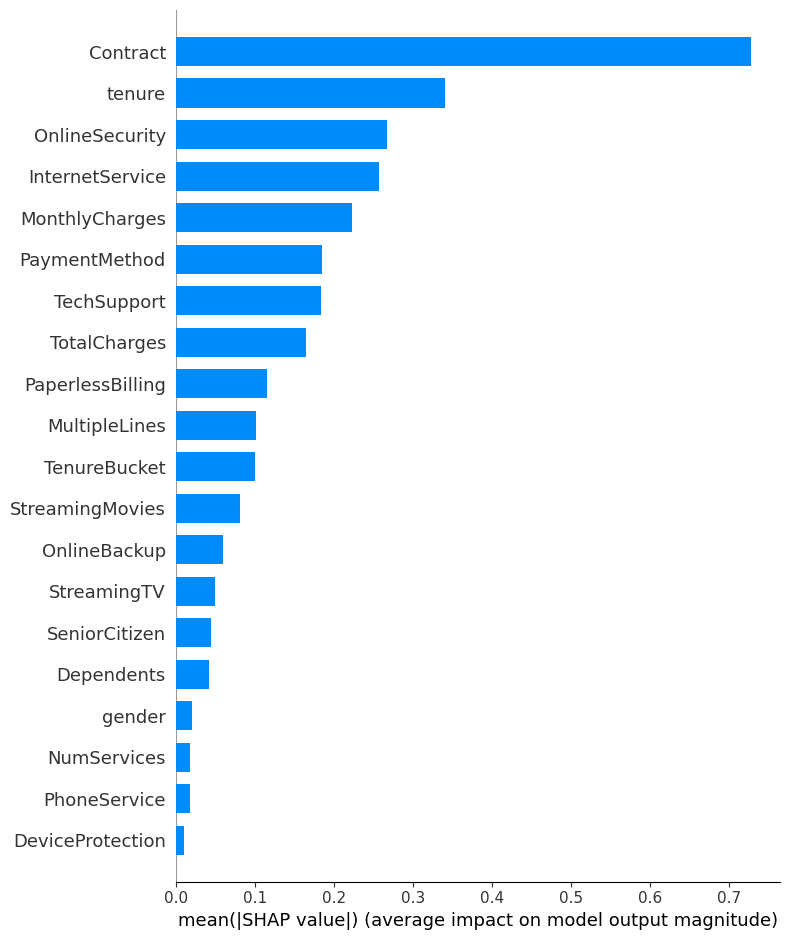

In [12]:
shap.summary_plot(shap_values, X_test, plot_type='bar')

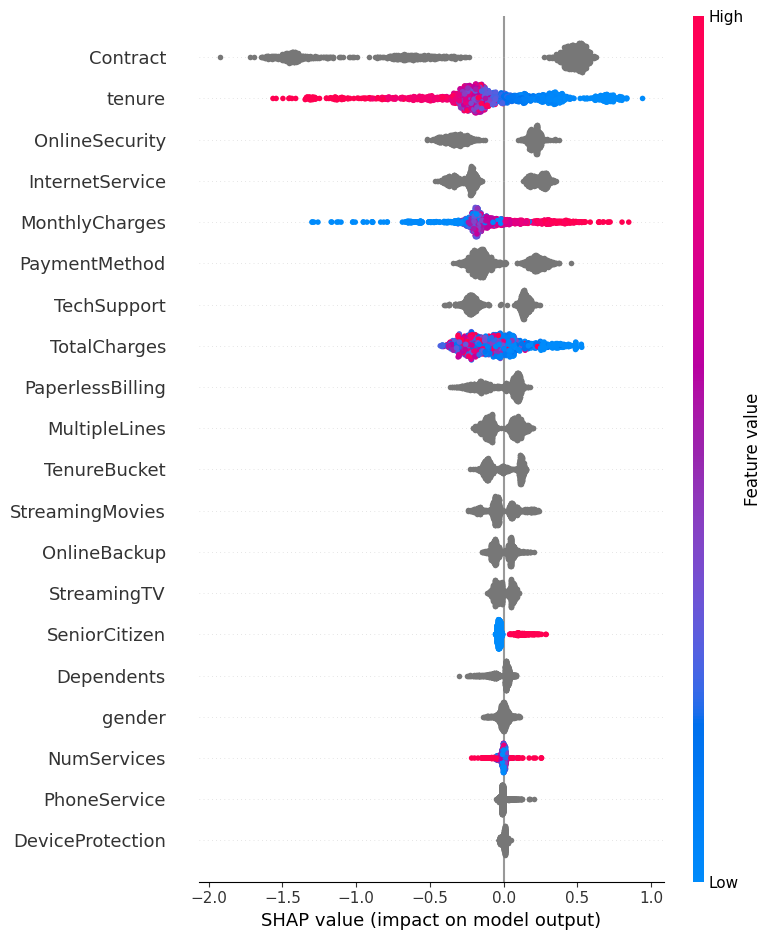

In [13]:
shap.summary_plot(shap_values, X_test)

C:\Users\Ritik Chauhan\AppData\Local\Temp\ipykernel_28348\1664960436.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  contract_shap.groupby('Contract')['SHAP_value'].mean().sort_values().plot(kind='barh')


<Axes: ylabel='Contract'>

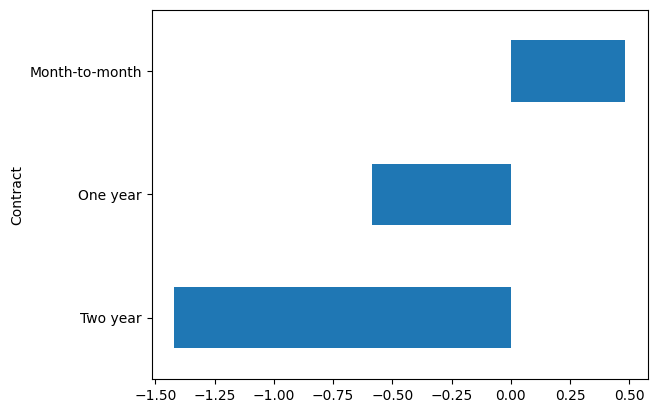

In [14]:
import pandas as pd

contract_shap = pd.DataFrame({
    'Contract': X_test['Contract'].values,
    'SHAP_value': shap_values[:, X_test.columns.get_loc('Contract')].values
})

contract_shap.groupby('Contract')['SHAP_value'].mean().sort_values().plot(kind='barh')

In [15]:
# Let's find a customer the model thinks is high-risk, to make a good example
idx = y_pred_proba_w.argmax()   # index of the highest predicted churn probability in the test set

print("Predicted churn probability:", y_pred_proba_w[idx])
print("Actually churned?", y_test.iloc[idx])
print("\nThis customer's details:")
print(X_test.iloc[idx])

Predicted churn probability: 0.99621433
Actually churned? 1

This customer's details:
gender                          Male
SeniorCitizen                      1
Partner                          Yes
Dependents                        No
tenure                             7
PhoneService                     Yes
MultipleLines                    Yes
InternetService          Fiber optic
OnlineSecurity                    No
OnlineBackup                      No
DeviceProtection                 Yes
TechSupport                       No
StreamingTV                      Yes
StreamingMovies                  Yes
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
MonthlyCharges                 99.25
TotalCharges                  665.45
TenureBucket                  0-1 yr
NumServices                        3
Name: 2631, dtype: object


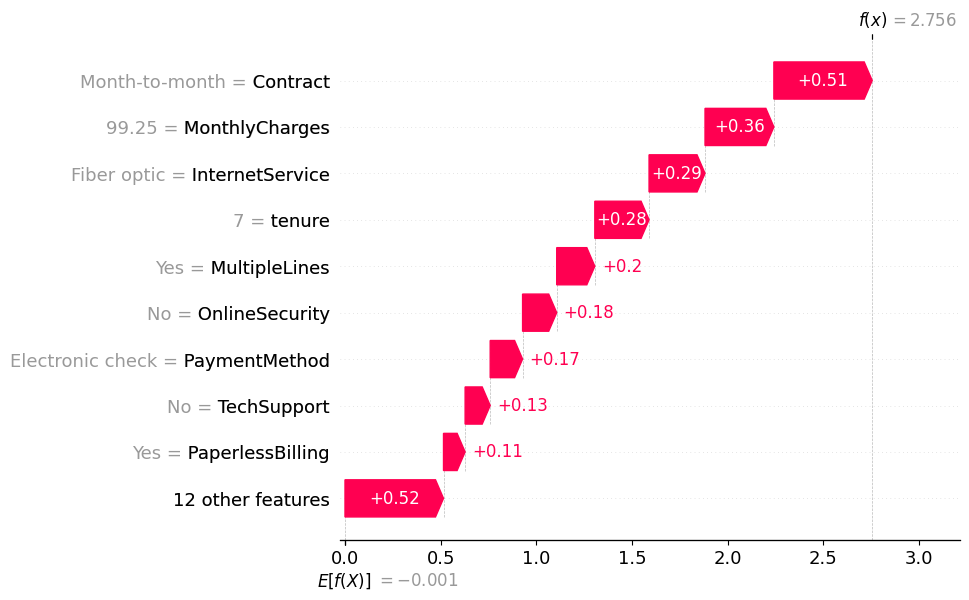

In [16]:
shap.plots.waterfall(shap_values[idx])